# Core figures for the report
Presentation only: every number comes from the saved results files.

In [1]:
import sys, pathlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'analysis'))
from research_style import setup, STRAT_COL, STRAT_MARK, shade_test, save, INK, GRID
from stats import nw_t, block_boot_ci
setup()
FIG = ROOT / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
END = 20231231
FIT, OOS = '2022\u20132023 (fitting period)', '2024 (out-of-sample)'
NAMES = {'S3': 'Option-flow stock selection', 'S2': 'Earnings-announcement drift', 'S1': 'Pre-earnings premium'}
VAR = {'S1': 'S1_hedged_5', 'S2': 'S2_hedged_h20', 'S3': 'S3_all_h1'}
CP = '#555555'   # portfolio colour (grey-black, distinct from strategies)
def todt(d): return pd.to_datetime(d.astype(str), format='%Y%m%d')
sc = pd.read_csv(ROOT/'results/scorecard_daily.csv'); sc['period'] = sc.period.map({'fitting': 'dev', 'out-of-sample': 'test'})  # short period labels used below
def SR(v, p): return float(sc[(sc.variant==v)&(sc.period==p)].sharpe.iloc[0])
d3 = pd.read_csv(ROOT/'results/option_flow_daily.csv'); de = pd.read_csv(ROOT/'results/earnings_events_daily.csv')
daily = pd.concat([d3, de])
pe = pd.read_csv(ROOT/'results/portfolio/portfolio_daily_excess.csv', index_col=0)

## Figure 1

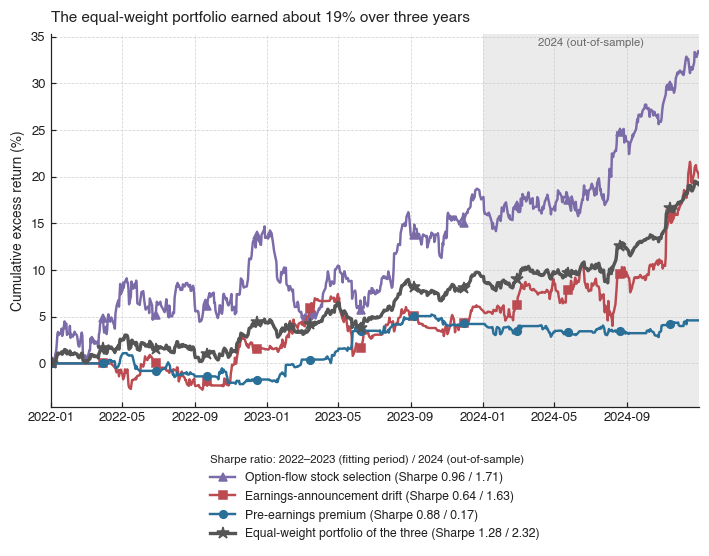

{'S3': np.float64(33.38), 'S2': np.float64(19.92), 'S1': np.float64(4.61), 'P': np.float64(19.17)} {'S1': (0.88, 0.17), 'S2': (0.64, 1.63), 'S3': (0.96, 1.71)} 1.28 2.32


In [2]:
def fmt_sr(a,b): return f'Sharpe {a:.2f} / {b:.2f}'
fig, ax = plt.subplots(figsize=(7.6, 4.4))
idx = pe.index
shade_test(ax, pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'), label='2024 (out-of-sample)', label_y=.99)
ends = {}
for k in ['S3','S2','S1']:
    s = daily[daily.variant==VAR[k]].set_index('date').ret.reindex(idx).fillna(0)
    cum = ((1+s).cumprod()-1)*100; ends[k]=cum.iloc[-1]
    lab = f"{NAMES[k]} ({fmt_sr(SR(VAR[k],'dev'), SR(VAR[k],'test'))})"
    ax.plot(todt(idx), cum.values, color=STRAT_COL[k], marker=STRAT_MARK[k], markevery=60, ms=5, label=lab)
p = pe['1/N | static']
def sh(x): return x.mean()/x.std()*np.sqrt(252)
pl = f"Equal-weight portfolio of the three ({fmt_sr(sh(p[idx<=END]), sh(p[idx>END]))})"
pc = ((1+p).cumprod()-1)*100; ends['P']=pc.iloc[-1]
ax.plot(todt(idx), pc.values, color=CP, marker='*', markevery=60, ms=8, lw=2.2, ls='-', label=pl)
ax.set_ylabel('Cumulative excess return (%)'); ax.set_xlabel('')
ax.set_title('The equal-weight portfolio earned about %.0f%% over three years' % ends['P'], pad=8)
ax.set_xlim(pd.Timestamp('2022-01-01'), pd.Timestamp('2024-12-31'))
ax.legend(title='Sharpe ratio: 2022\u20132023 (fitting period) / 2024 (out-of-sample)', title_fontsize=7.5, loc='upper center', bbox_to_anchor=(.5,-.1), ncol=1, alignment='left')
save(fig, FIG/'fig_core_curves.png'); plt.show()
print({k:round(v,2) for k,v in ends.items()}, {k:(round(SR(VAR[k],'dev'),2), round(SR(VAR[k],'test'),2)) for k in VAR}, round(sh(p[idx<=END]),2), round(sh(p[idx>END]),2))

**Figure 1.** The equal-weight portfolio gained about 19.2% over 2022–2024 with Sharpe 1.28 in the fitting period and 2.32 out-of-sample, while the pre-earnings premium faded to a Sharpe of 0.17 in 2024.

## Figure 2

dev 3.64 4.37 1.63
holdout 11.98 10.11 2.32


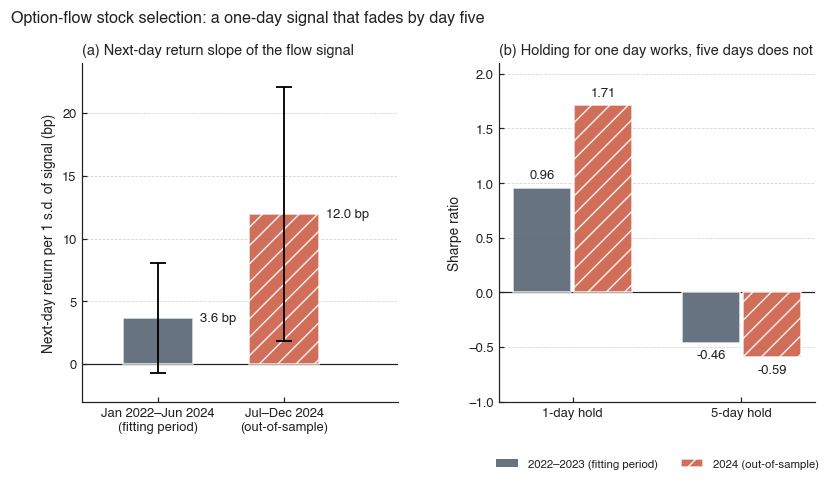

{('S3_all_h1', 'dev'): 0.96, ('S3_all_h1', 'test'): 1.71, ('S3_all_h5', 'dev'): -0.46, ('S3_all_h5', 'test'): -0.59}


In [3]:
fm = pd.read_csv(ROOT/'results/flow_fama_macbeth.csv'); fm['period'] = fm.period.map({'fitting': 'dev', 'out-of-sample': 'holdout'}); fm = fm.set_index('period')
fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 4.0), gridspec_kw=dict(wspace=.32))
cols = {'dev': '#4D5B6B', 'holdout': '#C8553D'}; hat = {'dev': '', 'holdout': '//'}
labs = {'dev': 'Jan 2022\u2013Jun 2024\n(fitting period)', 'holdout': 'Jul\u2013Dec 2024\n(out-of-sample)'}
for i, p_ in enumerate(['dev','holdout']):
    m = fm.loc[p_,'mean_slope']*1e4; hw = 1.96*abs(m/fm.loc[p_,'nw_t'])
    a.bar(i, m, .55, color=cols[p_], alpha=.85, hatch=hat[p_], edgecolor='white', zorder=3)
    a.errorbar(i, m, yerr=hw, fmt='none', ecolor='k', capsize=5, capthick=1.2, elinewidth=1.2, zorder=4)
    a.text(i+.33, m, f'{m:.1f} bp', va='center', ha='left', fontsize=8.5)
    print(p_, round(m,2), round(hw,2), round(fm.loc[p_,'nw_t'],2))
a.set_xticks([0,1]); a.set_xticklabels([labs['dev'], labs['holdout']]); a.set_xlim(-.6,1.9)
a.axhline(0, color=INK, lw=.8); a.set_ylim(-3, 24)
a.set_ylabel('Next-day return per 1 s.d. of signal (bp)')
a.set_title('(a) Next-day return slope of the flow signal', fontsize=9.5)
a.grid(axis='x', visible=False)
v = [('S3_all_h1','1-day hold'),('S3_all_h5','5-day hold')]
w=.36
for j,(vn,ln) in enumerate(v):
    for i,(p_,pn) in enumerate([('dev','dev'),('test','test')]):
        val = SR(vn,p_); x = j + (i-.5)*w
        b.bar(x, val, w*.95, color=cols['dev' if i==0 else 'holdout'], alpha=.85, hatch=['','//'][i], edgecolor='white', zorder=3)
        b.text(x, val + (.06 if val>=0 else -.06), f'{val:.2f}', ha='center', va='bottom' if val>=0 else 'top', fontsize=8.5)
b.axhline(0, color=INK, lw=.8); b.set_xticks([0,1]); b.set_xticklabels([v[0][1], v[1][1]])
b.set_ylim(-1.0, 2.1); b.set_ylabel('Sharpe ratio'); b.grid(axis='x', visible=False)
b.set_title('(b) Holding for one day works, five days does not', fontsize=9.5)
b.legend(handles=[Patch(facecolor=cols['dev'], alpha=.85, label=FIT), Patch(facecolor=cols['holdout'], alpha=.85, hatch='//', edgecolor='white', label=OOS)], loc='upper center', bbox_to_anchor=(.5,-.14), ncol=2, fontsize=7.5)
fig.suptitle('Option-flow stock selection: a one-day signal that fades by day five', x=.05, ha='left', y=1.0, fontsize=10.5)
save(fig, FIG/'fig_flow.png'); plt.show()
print({(vn,p_):round(SR(vn,p_),2) for vn,_ in v for p_ in ['dev','test']})

**Figure 2.** The flow signal's slope was 3.6 bp per s.d. in Jan 2022–Jun 2024 and 12.0 bp in Jul–Dec 2024, and the one-day-hold strategy had Sharpe 0.96 then 1.71 while the five-day hold was negative (-0.46, -0.59).

## Figure 3

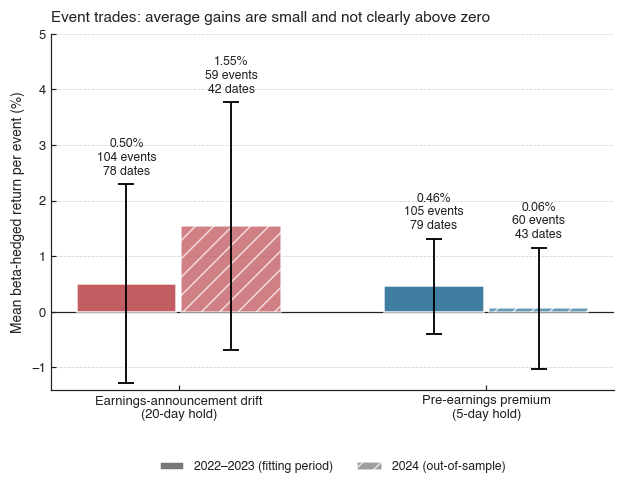

{('S2', 0): (np.float64(0.5), np.float64(1.79), 104, 78), ('S2', 1): (np.float64(1.55), np.float64(2.23), 59, 42), ('S1', 0): (np.float64(0.46), np.float64(0.86), 105, 79), ('S1', 1): (np.float64(0.06), np.float64(1.1), 60, 43)}


In [4]:
tr = pd.read_csv(ROOT/'results/earnings_events_trades.csv'); tr = tr[tr.status=='filled']
fig, ax = plt.subplots(figsize=(6.6, 4.2))
items = [('S2','S2_hedged_h20'),('S1','S1_hedged_5')]
w = .34; res = {}
for j,(k,vn) in enumerate(items):
    t = tr[tr.variant==vn]
    for i,(pn,sel) in enumerate([(FIT, t.d_out<=END),(OOS, t.d_out>END)]):
        tt = t[sel]; g = tt.groupby('d_out').r_hedged.mean()*100
        m = tt.r_hedged.mean()*100; hw = 1.96*g.std(ddof=1)/np.sqrt(len(g)); x = j+(i-.5)*w
        ax.bar(x, m, w*.95, color=STRAT_COL[k], alpha=.9 if i==0 else .7, hatch=['','//'][i], edgecolor='white', zorder=3)
        ax.errorbar(x, m, yerr=hw, fmt='none', ecolor='k', capsize=5, capthick=1.2, elinewidth=1.2, zorder=4)
        ax.text(x, m+hw+.12, f'{m:.2f}%\n{len(tt)} events\n{len(g)} dates', ha='center', va='bottom', fontsize=8)
        ev = pd.read_csv(ROOT/'results/scorecard_events.csv'); ev['period'] = ev.period.map({'fitting': 'dev', 'out-of-sample': 'test'}); ev = ev[(ev.variant==vn)&(ev.period==['dev','test'][i])]; assert abs(tt.r_hedged.mean()-float(ev['mean'].iloc[0])) < 1e-4, (vn, i, tt.r_hedged.mean(), ev['mean'].iloc[0])
        res[(k,i)] = (round(m,2), round(hw,2), len(tt), len(g))
ax.axhline(0, color=INK, lw=.8)
ax.set_xticks([0,1]); ax.set_xticklabels(['Earnings-announcement drift\n(20-day hold)','Pre-earnings premium\n(5-day hold)'])
ax.set_ylabel('Mean beta-hedged return per event (%)'); ax.set_ylim(-1.4, 5.0); ax.grid(axis='x', visible=False)
ax.set_title('Event trades: average gains are small and not clearly above zero', pad=8)
ax.legend(handles=[Patch(facecolor='#777', hatch='', edgecolor='white', label=FIT), Patch(facecolor='#777', alpha=.7, hatch='//', edgecolor='white', label=OOS)], loc='upper center', bbox_to_anchor=(.5,-.17), ncol=2)
save(fig, FIG/'fig_events.png'); plt.show(); print(res)

**Figure 3.** Mean beta-hedged returns per event were 0.50% (104 events) then 1.55% (59 events) for earnings-announcement drift and 0.46% (105 events) then 0.06% (60 events) for the pre-earnings premium, with every 95% interval including zero.

## Figure 4

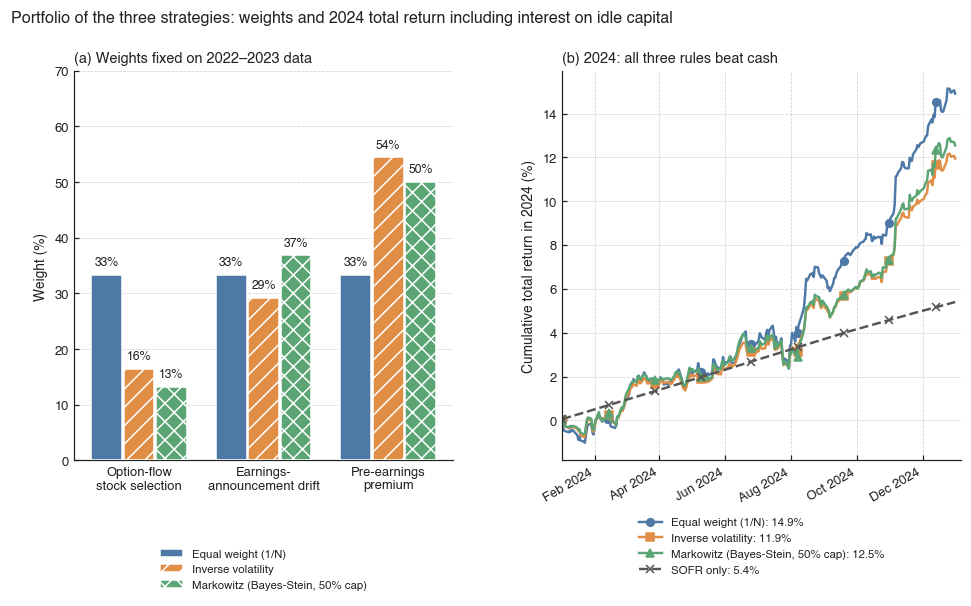

{'1/N': np.float64(14.91), 'inverse vol': np.float64(11.94), 'Markowitz (Bayes-Stein, cap 50%)': np.float64(12.55), 'sofr': np.float64(5.4)}
                      1/N  inverse vol  Markowitz (Bayes-Stein, cap 50%)
S1 pre-earn premium  33.3         54.4                              50.0
S2 EAR drift         33.3         29.1                              36.8
S3 option flow (1d)  33.3         16.4                              13.2


In [5]:
W = pd.read_csv(ROOT/'results/portfolio/weights_static.csv', index_col=0)
rules = ['1/N','inverse vol','Markowitz (Bayes-Stein, cap 50%)']
rl = {'1/N':'Equal weight (1/N)','inverse vol':'Inverse volatility','Markowitz (Bayes-Stein, cap 50%)':'Markowitz (Bayes-Stein, 50% cap)'}
rc = {'1/N':'#4E79A7','inverse vol':'#E08E45','Markowitz (Bayes-Stein, cap 50%)':'#5BA574'}
rm = {'1/N':'o','inverse vol':'s','Markowitz (Bayes-Stein, cap 50%)':'^'}
rh = {'1/N':'','inverse vol':'//','Markowitz (Bayes-Stein, cap 50%)':'xx'}
fig, (a, b) = plt.subplots(1, 2, figsize=(10.4, 4.6), gridspec_kw=dict(wspace=.28, width_ratios=[1,1.05]))
order = ['S3 option flow (1d)','S2 EAR drift','S1 pre-earn premium']; xl = [NAMES['S3'],NAMES['S2'],NAMES['S1']]
xl = ['Option-flow\nstock selection','Earnings-\nannouncement drift','Pre-earnings\npremium']
w = .26
for i,r in enumerate(rules):
    for j,s in enumerate(order):
        v = W.loc[s, r]*100; x = j+(i-1)*w
        a.bar(x, v, w*.95, color=rc[r], hatch=rh[r], edgecolor='white', zorder=3, label=rl[r] if j==0 else None)
        a.text(x, v+1.2, f'{v:.0f}%', ha='center', va='bottom', fontsize=8)
a.set_xticks(range(3)); a.set_xticklabels(xl); a.set_ylim(0, 70); a.set_ylabel('Weight (%)'); a.grid(axis='x', visible=False)
a.set_title('(a) Weights fixed on 2022\u20132023 data', fontsize=9.5)
a.legend(loc='upper center', bbox_to_anchor=(.5,-.2), ncol=1, fontsize=7.5)
m24 = pe.index>END; sofr = pe.loc[m24,'sofr']; fin={}
dd = todt(pe.index[m24])
for r in rules:
    c = ((1+pe.loc[m24, r+' | static'] + sofr).cumprod()-1)*100
    fin[r]=c.iloc[-1]
    b.plot(dd, c.values, color=rc[r], marker=rm[r], markevery=30, ms=5, label=f'{rl[r]}: {c.iloc[-1]:.1f}%')
cs = ((1+sofr).cumprod()-1)*100; fin['sofr']=cs.iloc[-1]
b.plot(dd, cs.values, color='#555555', ls='--', marker='x', markevery=30, ms=5, label=f'SOFR only: {cs.iloc[-1]:.1f}%')
b.set_ylabel('Cumulative total return in 2024 (%)'); b.set_title('(b) 2024: all three rules beat cash', fontsize=9.5)
b.legend(loc='upper center', bbox_to_anchor=(.5,-.12), ncol=1, fontsize=7.5)
b.set_xlim(dd[0], dd[-1] + pd.Timedelta(days=5)); import matplotlib.dates as mdt; b.xaxis.set_major_formatter(mdt.DateFormatter('%b %Y')); b.xaxis.set_major_locator(mdt.MonthLocator(interval=2)); plt.setp(b.get_xticklabels(), rotation=30, ha='right')
fig.suptitle('Portfolio of the three strategies: weights and 2024 total return including interest on idle capital', x=.07, ha='left', y=1.0, fontsize=10.5)
save(fig, FIG/'fig_portfolio.png'); plt.show()
summ = pd.read_csv(ROOT/'results/portfolio/allocation_summary.csv'); summ = summ[(summ.schedule=='static')&(summ.period=='2024 (out-of-sample)')].set_index('method')
for r in rules: assert abs(fin[r]/100 - summ.loc[r,'ann_total']) < 1e-4, (r, fin[r], summ.loc[r,'ann_total'])
assert abs(fin['sofr']/100 - 0.0540) < 1e-4, fin['sofr']
print({k:round(v,2) for k,v in fin.items()}); print((W[rules]*100).round(1))

**Figure 4.** Fitted on 2022–2023, the pre-earnings premium gets 33%, 54% and 50% under equal weight, inverse volatility and Markowitz, and in 2024 the rules returned 14.9%, 11.9% and 12.5% against 5.4% for SOFR alone.